# Prediction evaluation

This dataframe explores the data recorded from predicting presence without adaptation.

The dataset loaded here is located in "/data/running.pickle". It can be created / updated by running the simple scenario with command RUN.

In [1]:
# set working directoy to root directory of the project
if not "working_directory_corrected" in vars():
    %cd ..
    %cd ..
    %cd ..
    working_directory_corrected = True
    
import pandas as pd
from datetime import datetime
from sklearn.model_selection import train_test_split
from sklearn import metrics
import matplotlib.pyplot as plt

from examples.simple_scenario.src.simple_scenario import create_simple_scenario

c:\Users\frank\Documents\Research\projects\evohome\environment\lib\site-packages\IPython\core\magics\osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


c:\Users\frank\Documents\Research\projects\evohome\examples\simple_scenario
c:\Users\frank\Documents\Research\projects\evohome\examples
c:\Users\frank\Documents\Research\projects\evohome


## Data Loading

Below, we load the data. 

For this notebook we keep the following values from our dataset:
- weekday: the day of the week
- hour: the hour of the day
- minute: the minute of the hour
- room_x: the actual value of room x
- prediction_x: the predicted value of room x

Additional data processing:
- For look-ahead scenarios the first few predicted values are typically NaN values. We drop them from the dataset.
- We convert predictions to type integer (booleans are represented as 0 = false, 1 = true)
- We convert the data frame into a time series by indexing over the date column.

In [2]:
# create scenario and load room names. This assumes the scenario has not changes since data was recorded.
scenario = create_simple_scenario()
room_names = scenario.get_room_names()
nr_rooms = len(room_names)

# load dataset, typecheck and column drops
data_frame = pd.read_pickle("examples/simple_scenario/data/running.pickle")
data_frame.drop(labels = ["adaptation_time"], axis = 1, inplace= True)
data_frame.dropna(axis = 0, how = "any", inplace = True)
for index in range(nr_rooms):
    column = "prediction_" + str(index)
    data_frame[column] = data_frame[column].astype('int32')

# index dataset as time series
data_frame["date"] = pd.to_datetime(data_frame["date"])
data_frame.set_index(pd.DatetimeIndex(data_frame["date"]), inplace=True)
data_frame.drop("date", axis = 1, inplace= True)

# print some statistics and data
print(f"The dataframe has {len(data_frame)} samples.")
print(f"The example scenario has {nr_rooms} rooms.")
print("below are five random samples")
data_frame


The dataframe has 1036740 samples.
The example scenario has 11 rooms.
below are five random samples


,weather,prediction_time,room_0,prediction_0,room_1,prediction_1,room_2,prediction_2,room_3,prediction_3,...,prediction_7,room_8,prediction_8,room_9,prediction_9,room_10,prediction_10,weekday,hour,minute
date,,,,,,,,,,,,,,,,,,,,,
2020-06-01 01:00:00,0.526433,0.000454,0,0,0,0,1,1,1,1,...,0,0,0,0,0,0,0,0,1,0
2020-06-01 01:01:00,0.526699,0.000454,0,0,0,0,1,1,1,1,...,0,0,0,0,0,0,0,0,1,1
2020-06-01 01:02:00,0.526970,0.000207,0,0,0,0,1,1,1,1,...,0,0,0,0,0,0,0,0,1,2
2020-06-01 01:03:00,0.527246,0.000140,0,0,0,0,1,1,1,1,...,0,0,0,0,0,0,0,0,1,3
2020-06-01 01:04:00,0.527525,0.000130,0,0,0,0,1,1,1,1,...,0,0,0,0,0,0,0,0,1,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-05-21 23:55:00,0.278926,0.000096,0,0,0,0,1,1,1,1,...,0,0,0,0,0,0,0,5,23,55
2022-05-21 23:56:00,0.278907,0.000097,0,0,0,0,1,1,1,1,...,0,0,0,0,0,0,0,5,23,56
2022-05-21 23:57:00,0.288892,0.000095,0,0,0,0,1,1,1,1,...,0,0,0,0,0,0,0,5,23,57


## Score Development

Per default, scores in the datset are in minute intervals. To keep things manageable for the visualization, we calculate F1 scores per day in the cell below.

The result is a dataset "day_scores" that contains the day-averaged F1 scores for each room as well as an overall average F1 score for each day.

In [3]:
def get_f1(data_frame):
    """
        Calculate F1 score of a dataframe
        Args: 
            - data_frame: a time series with prediction_n and room_n as keys, for all rooms n.
        returns:
            - a list of floating point numbers, indexed by room number, representing the overall F1 score of a room.
    """
    f1s = []
    for index in range(nr_rooms):
        f1s.append(metrics.f1_score(y_pred = data_frame["prediction_" + str(index)], 
                                                 y_true = data_frame["room_" + str(index)],
                                                 zero_division = 1))
    return f1s

# calculate day averages
by_day_data = data_frame.groupby(data_frame.index.date)
days = [group[0] for group in by_day_data]
day_scores = [get_f1(group[1]) for group in by_day_data]
day_scores = pd.DataFrame(day_scores, index=pd.DatetimeIndex(days))

# overall average
day_scores["average"] = day_scores[0]
for index in range(1,nr_rooms):
    day_scores["average"] += day_scores[index]
day_scores["average"] /= nr_rooms

day_scores


,0,1,2,3,4,5,6,7,8,9,10,average
2020-06-01,1.0,1.0,0.932665,0.925952,0.997917,0.076923,0.193548,0.983333,0.647059,0.684411,0.965834,0.764331
2020-06-02,1.0,1.0,0.926299,0.926526,0.853291,0.148148,0.258065,0.983051,0.923077,0.559242,0.980822,0.778047
2020-06-03,1.0,1.0,0.903442,0.996487,0.998148,0.080000,0.125000,0.983333,0.968622,0.727273,0.991094,0.797582
2020-06-04,1.0,1.0,0.949337,0.930173,0.932660,0.071429,0.187500,0.983333,0.623158,0.959620,0.951123,0.780758
2020-06-05,1.0,1.0,0.906902,0.943050,0.949429,0.000000,0.133333,0.983333,0.904074,0.712551,0.867419,0.763645
...,...,...,...,...,...,...,...,...,...,...,...,...
2022-05-17,1.0,1.0,0.939959,0.943696,0.934952,0.068966,0.102564,0.391753,0.666667,0.012903,0.785538,0.622454
2022-05-18,1.0,1.0,0.866764,0.929331,0.948109,0.083333,0.117647,0.229249,0.792614,0.432653,0.757176,0.650625
2022-05-19,1.0,1.0,0.884553,0.907595,0.870266,0.133333,0.205128,0.247863,0.711679,0.966667,0.724960,0.695640
2022-05-20,1.0,1.0,0.948854,0.916608,0.857348,0.133333,0.114286,0.308511,0.742857,0.749280,0.895880,0.696996


We now visualize the average accuracy per day as it develops over time.

The visualized time frame below can be adjusted by changint start and end date. The earliest start date is 2020-06-01 and the latest end date 2022-05-21


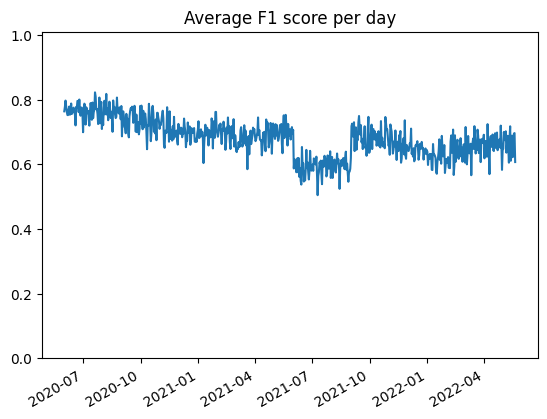

In [ ]:

start_date = datetime(year = 2020,month=6, day = 1)
end_date = datetime(year = 2022,month=5, day = 21)

fig, ax = plt.subplots()
ax.plot(day_scores[start_date:end_date]["average"])
ax.set_title("Average F1 score per day")
ax.set_ylim([0.0, 1.01])
fig.autofmt_xdate()
plt.show()

Below we visualize the accuracy for each room

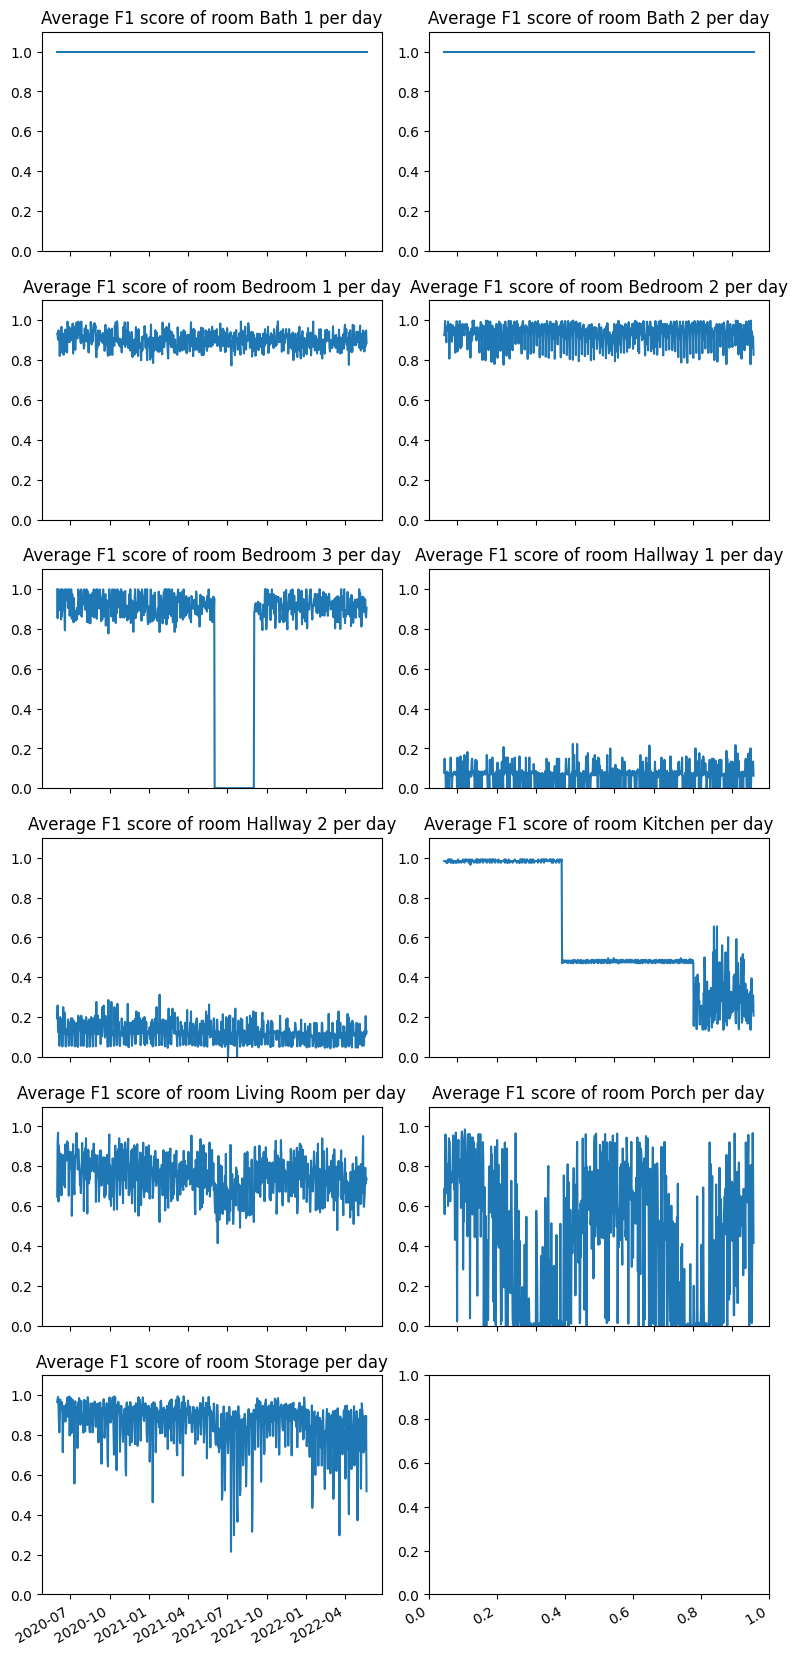

In [5]:
start_date = datetime(year = 2020,month=6, day = 1)
end_date = datetime(year = 2022,month=5, day = 22)

nr_cols = 2

fig, subplots = plt.subplots(ncols= nr_cols,nrows= (nr_rooms+1) //nr_cols, figsize = (8,20))

for room_index in range(nr_rooms):
    ax = subplots[room_index//nr_cols][room_index% nr_cols]
    ax.set_title(f"Average F1 score of room {room_names[room_index]} per day")
    ax.plot(day_scores[start_date:end_date][room_index])
    ax.set_ylim([0, 1.1])
    
fig.tight_layout()
fig.autofmt_xdate()
plt.show()

## Prediction Time development

The simulation also records prediction time. Below we plot the development of prediction time in seconds over the scenario period.

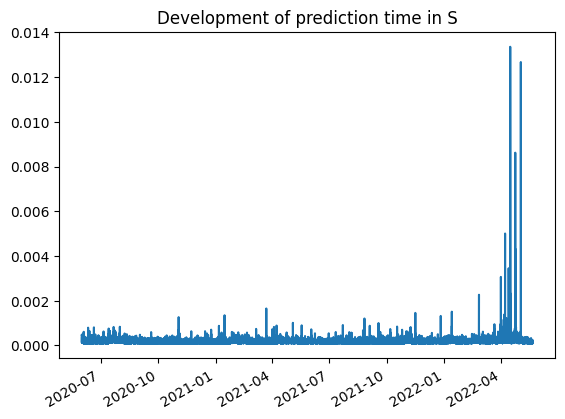

In [7]:

start_date = datetime(year = 2020,month=6, day = 1)
end_date = datetime(year = 2022,month=5, day = 22)

fig, ax = plt.subplots()
ax.plot(data_frame["prediction_time"])
ax.set_title("Development of prediction time in S")
fig.autofmt_xdate()
plt.show()